In [5]:
import pandas as pd
import numpy as np

print("Task 2 Started Successfully!")



Task 2 Started Successfully!


In [7]:
import pandas as pd

df = pd.read_csv("dataset/titanic.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (891, 12)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [9]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [10]:
# Fill missing Age values with the median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing Embarked values with the most frequent value
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Drop Cabin because it contains many missing values
df = df.drop(columns=["Cabin"])

print("Missing values handled successfully!")

Missing values handled successfully!


In [11]:
print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [12]:
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 0


In [13]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("Dataset Shape After Removing Duplicates:", df.shape)

Duplicates removed successfully!
Dataset Shape After Removing Duplicates: (891, 11)


In [14]:
df = df.drop(columns=["PassengerId", "Name", "Ticket"])

print("Unnecessary columns removed successfully!")
print("\nRemaining Columns:")
print(df.columns.tolist())


Unnecessary columns removed successfully!

Remaining Columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [15]:
# Convert categorical columns into numerical values

df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

df = pd.get_dummies(df, columns=["Embarked"], dtype=int)

print("Categorical data converted successfully!")

print("\nUpdated Columns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Categorical data converted successfully!

Updated Columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

First 5 Rows:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


In [16]:
print("Final Dataset Shape:", df.shape)

print("\nFinal Column Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Final Dataset Shape: (891, 10)

Final Column Names:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

Missing Values:
Survived      0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked_C    0
Embarked_Q    0
Embarked_S    0
dtype: int64

Data Types:
Survived        int64
Pclass          int64
Sex             int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Embarked_C      int64
Embarked_Q      int64
Embarked_S      int64
dtype: object


In [17]:
df.to_csv("cleaned_data/titanic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [18]:
print("Statistical Summary:")
display(df.describe())

Statistical Summary:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,0.352413,29.361582,0.523008,0.381594,32.204208,0.188552,0.086420,0.725028
std,0.486592,0.836071,0.477990,13.019697,1.102743,0.806057,49.693429,0.391372,0.281141,0.446751
min,0.000000,1.000000,0.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,0.000000,22.000000,0.000000,0.000000,7.910400,0.000000,0.000000,0.000000
50%,0.000000,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,0.000000,0.000000,1.000000
75%,1.000000,3.000000,1.000000,35.000000,1.000000,0.000000,31.000000,0.000000,0.000000,1.000000
max,1.000000,3.000000,1.000000,80.000000,8.000000,6.000000,512.329200,1.000000,1.000000,1.000000


In [19]:
survival_counts = df["Survived"].value_counts()

print("Survival Count:")
print(survival_counts)

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64


In [20]:
survival_percentage = df["Survived"].value_counts(normalize=True) * 100

print("Survival Percentage:")
print(survival_percentage)

Survival Percentage:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


In [21]:
gender_survival = df.groupby("Sex")["Survived"].mean() * 100

print("Survival Percentage by Gender:")
print(gender_survival)

Survival Percentage by Gender:
Sex
0    18.890815
1    74.203822
Name: Survived, dtype: float64


In [22]:

class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival Percentage by Passenger Class:")
print(class_survival)

Survival Percentage by Passenger Class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


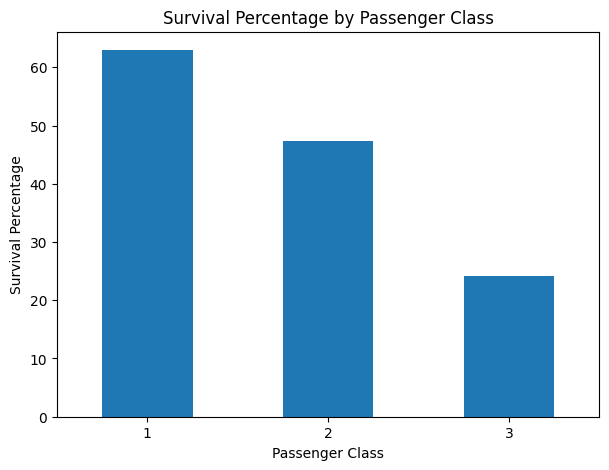

In [23]:
import matplotlib.pyplot as plt

class_survival = df.groupby("Pclass")["Survived"].mean() * 100

plt.figure(figsize=(7, 5))
class_survival.plot(kind="bar")

plt.title("Survival Percentage by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)
plt.show()

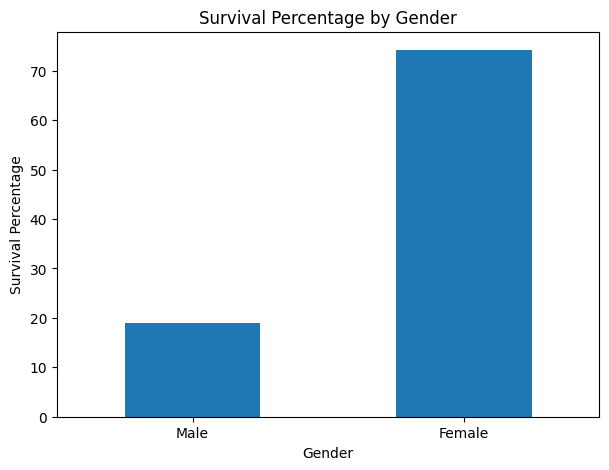

In [24]:
import matplotlib.pyplot as plt

gender_survival = df.groupby("Sex")["Survived"].mean() * 100

gender_survival.index = ["Male", "Female"]

plt.figure(figsize=(7, 5))
gender_survival.plot(kind="bar")

plt.title("Survival Percentage by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)
plt.show()

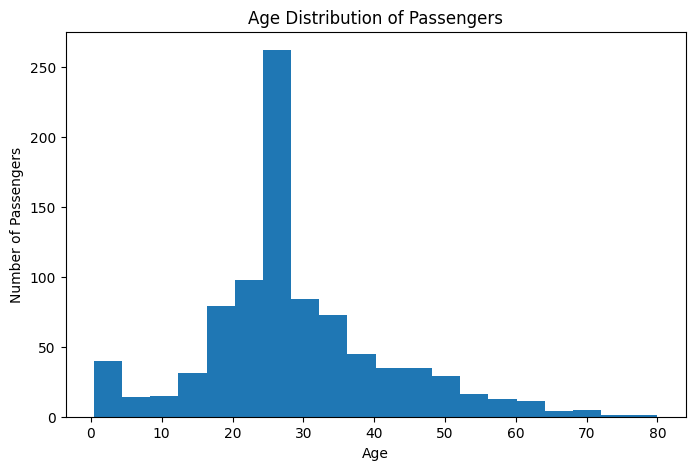

In [25]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=20)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [26]:
# Create age groups

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

# Calculate survival percentage by age group

age_survival = df.groupby("Age_Group", observed=False)["Survived"].mean() * 100

print("Survival Percentage by Age Group:")
print(age_survival)

Survival Percentage by Age Group:
Age_Group
Child          57.971014
Teenager       42.857143
Young Adult    35.327103
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64


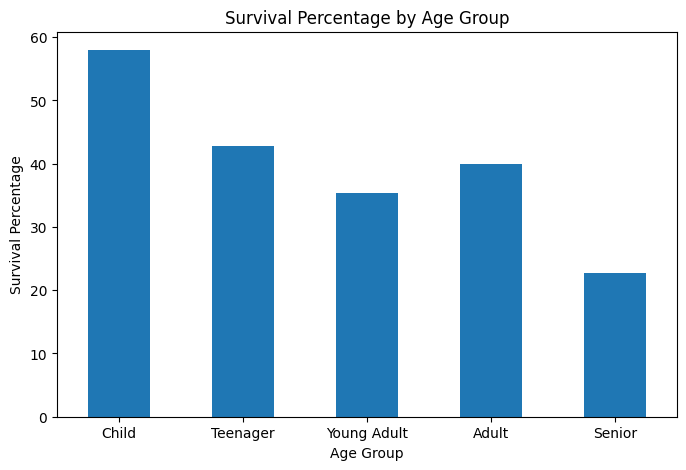

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

age_survival.plot(kind="bar")

plt.title("Survival Percentage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)

plt.show()

In [28]:
# Create Family Size column

df["Family_Size"] = df["SibSp"] + df["Parch"] + 1

print("Family Size column created successfully!")

display(df[["SibSp", "Parch", "Family_Size"]].head())

Family Size column created successfully!


,SibSp,Parch,Family_Size
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [29]:
# Calculate survival percentage by family size

family_survival = df.groupby("Family_Size")["Survived"].mean() * 100

print("Survival Percentage by Family Size:")
print(family_survival)

Survival Percentage by Family Size:
Family_Size
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64


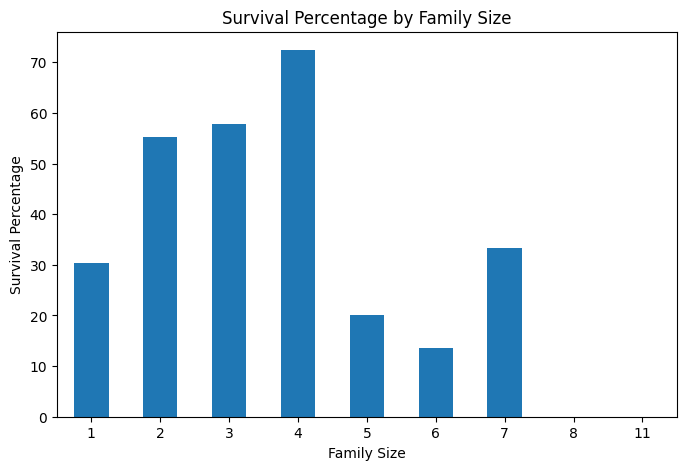

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

family_survival.plot(kind="bar")

plt.title("Survival Percentage by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)

plt.show()

In [31]:
# Calculate correlation matrix

correlation_matrix = df.corr(numeric_only=True)

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Family_Size
Survived,1.000000,-0.338481,0.543351,-0.064910,-0.035322,0.081629,0.257307,0.168240,0.003650,-0.149683,0.016639
Pclass,-0.338481,1.000000,-0.131900,-0.339898,0.083081,0.018443,-0.549500,-0.243292,0.221009,0.074053,0.065997
Sex,0.543351,-0.131900,1.000000,-0.081163,0.114631,0.245489,0.182333,0.082853,0.074115,-0.119224,0.200988
Age,-0.064910,-0.339898,-0.081163,1.000000,-0.233296,-0.172482,0.096688,0.030248,-0.031415,-0.006729,-0.245619
SibSp,-0.035322,0.083081,0.114631,-0.233296,1.000000,0.414838,0.159651,-0.059528,-0.026354,0.068734,0.890712
Parch,0.081629,0.018443,0.245489,-0.172482,0.414838,1.000000,0.216225,-0.011069,-0.081228,0.060814,0.783111
Fare,0.257307,-0.549500,0.182333,0.096688,0.159651,0.216225,1.000000,0.269335,-0.117216,-0.162184,0.217138
Embarked_C,0.168240,-0.243292,0.082853,0.030248,-0.059528,-0.011069,0.269335,1.000000,-0.148258,-0.782742,-0.046215
Embarked_Q,0.003650,0.221009,0.074115,-0.031415,-0.026354,-0.081228,-0.117216,-0.148258,1.000000,-0.499421,-0.058592
Embarked_S,-0.149683,0.074053,-0.119224,-0.006729,0.068734,0.060814,-0.162184,-0.782742,-0.499421,1.000000,0.077359


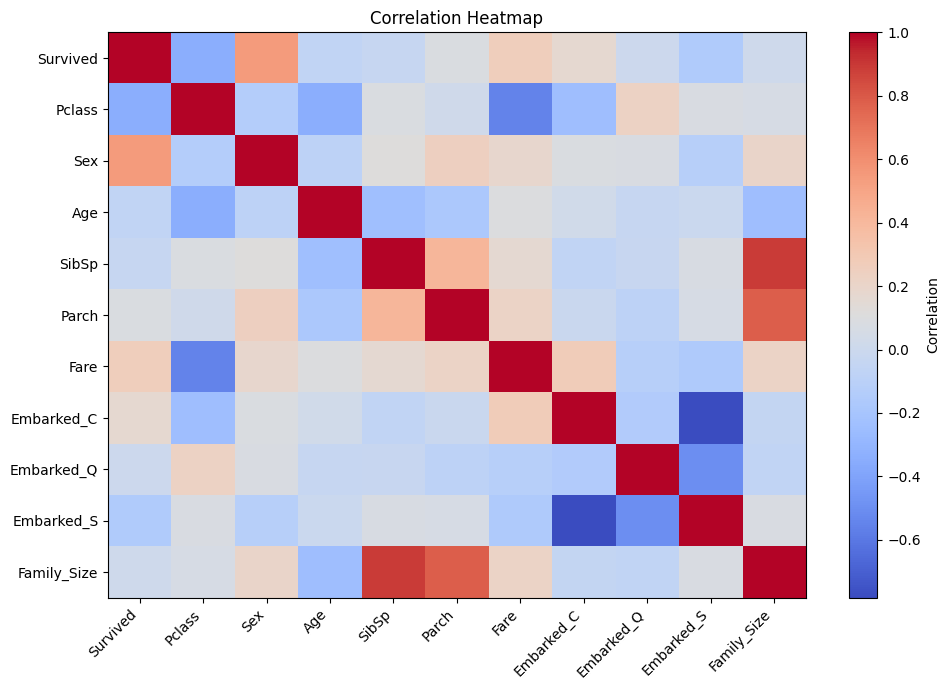

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, cmap="coolwarm", aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [33]:
# Save the final analyzed dataset

df.to_csv("cleaned_data/titanic_final.csv", index=False)

print("Final analyzed dataset saved successfully!")
print("File: cleaned_data/titanic_final.csv")

Final analyzed dataset saved successfully!
File: cleaned_data/titanic_final.csv


In [34]:
print("========== TITANIC DATA ANALYSIS INSIGHTS ==========\n")

print("1. Overall Survival:")
print(f"Survival Rate: {df['Survived'].mean() * 100:.2f}%")

print("\n2. Survival by Gender:")
print(gender_survival)

print("\n3. Survival by Passenger Class:")
print(class_survival)

print("\n4. Survival by Age Group:")
print(age_survival)

print("\n5. Survival by Family Size:")
print(family_survival)

print("\n====================================================")
print("Analysis completed successfully!")

========== TITANIC DATA ANALYSIS INSIGHTS ==========

1. Overall Survival:
Survival Rate: 38.38%

2. Survival by Gender:
Male      18.890815
Female    74.203822
Name: Survived, dtype: float64

3. Survival by Passenger Class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

4. Survival by Age Group:
Age_Group
Child          57.971014
Teenager       42.857143
Young Adult    35.327103
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64

5. Survival by Family Size:
Family_Size
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64

Analysis completed successfully!


In [35]:
print("========== FINAL CONCLUSION ==========\n")

print("• The overall survival rate of passengers was 38.38%.")
print("• Female passengers had a higher survival rate than male passengers.")
print("• First-class passengers had a higher survival rate compared with second- and third-class passengers.")
print("• Children had a relatively higher survival rate among the age groups analyzed.")
print("• Senior passengers had the lowest survival rate among the analyzed age groups.")
print("• Survival patterns varied based on gender, passenger class, age group, and family size.")

print("\n========== TASK 2 COMPLETED ==========")

========== FINAL CONCLUSION ==========

• The overall survival rate of passengers was 38.38%.
• Female passengers had a higher survival rate than male passengers.
• First-class passengers had a higher survival rate compared with second- and third-class passengers.
• Children had a relatively higher survival rate among the age groups analyzed.
• Senior passengers had the lowest survival rate among the analyzed age groups.
• Survival patterns varied based on gender, passenger class, age group, and family size.

========== TASK 2 COMPLETED ==========


# Veda Technology – Task 2
## Exploratory Data Analysis (EDA) on Titanic Dataset

### Objective
To explore the Titanic dataset, perform data cleaning, analyze passenger survival patterns, and visualize relationships between different features and survival.

### Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook


## 1. Dataset Loading

In [36]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (891, 12)

Column Names:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Age_Group', 'Family_Size']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   Survived     891 non-null    int64   
 1   Pclass       891 non-null    int64   
 2   Sex          891 non-null    int64   
 3   Age          891 non-null    float64 
 4   SibSp        891 non-null    int64   
 5   Parch        891 non-null    int64   
 6   Fare         891 non-null    float64 
 7   Embarked_C   891 non-null    int64   
 8   Embarked_Q   891 non-null    int64   
 9   Embarked_S   891 non-null    int64   
 10  Age_Group    891 non-null    category
 11  Family_Size  891 non-null    int64   
dtypes: category(1), float64(2), int64(9)
memory usage: 77.8 KB


## 2. Dataset Exploration

In [37]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked_C     0
Embarked_Q     0
Embarked_S     0
Age_Group      0
Family_Size    0
dtype: int64


## 3. Data Cleaning

In [38]:
print("Statistical Summary:")
display(df.describe())

Statistical Summary:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Family_Size
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,0.352413,29.361582,0.523008,0.381594,32.204208,0.188552,0.086420,0.725028,1.904602
std,0.486592,0.836071,0.477990,13.019697,1.102743,0.806057,49.693429,0.391372,0.281141,0.446751,1.613459
min,0.000000,1.000000,0.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,2.000000,0.000000,22.000000,0.000000,0.000000,7.910400,0.000000,0.000000,0.000000,1.000000
50%,0.000000,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,0.000000,0.000000,1.000000,1.000000
75%,1.000000,3.000000,1.000000,35.000000,1.000000,0.000000,31.000000,0.000000,0.000000,1.000000,2.000000
max,1.000000,3.000000,1.000000,80.000000,8.000000,6.000000,512.329200,1.000000,1.000000,1.000000,11.000000


## 4. Statistical Analysis

In [39]:
survival_counts = df["Survived"].value_counts()

print("Survival Count:")
print(survival_counts)

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64


## 5. Survival Analysis

<Axes: xlabel='Pclass'>

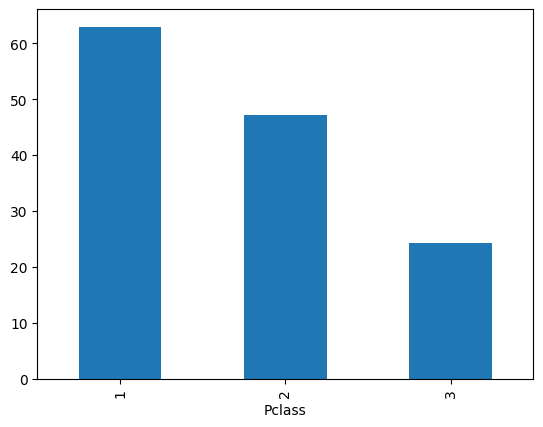

In [40]:
class_survival.plot(kind="bar")

## 6. Data Visualization

In [42]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

In [43]:
print(df[["Age", "Age_Group"]].head(10))

    Age    Age_Group
0  22.0  Young Adult
1  38.0        Adult
2  26.0  Young Adult
3  35.0  Young Adult
4  35.0  Young Adult
5  28.0  Young Adult
6  54.0        Adult
7   2.0        Child
8  27.0  Young Adult
9  14.0     Teenager


In [44]:
age_survival = df.groupby(
    "Age_Group",
    observed=False
)["Survived"].mean() * 100

print("Survival Percentage by Age Group:")
print(age_survival)

Survival Percentage by Age Group:
Age_Group
Child          57.971014
Teenager       42.857143
Young Adult    35.327103
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64


## 7. Age and Family Size Analysis

In [45]:
age_survival = df.groupby(
    "Age_Group",
    observed=False
)["Survived"].mean() * 100

print("Survival Percentage by Age Group:")
print(age_survival)

Survival Percentage by Age Group:
Age_Group
Child          57.971014
Teenager       42.857143
Young Adult    35.327103
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64


In [46]:
age_survival = df.groupby(
    "Age_Group",
    observed=False
)["Survived"].mean() * 100

print("Survival Percentage by Age Group:")
print(age_survival)

Survival Percentage by Age Group:
Age_Group
Child          57.971014
Teenager       42.857143
Young Adult    35.327103
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64


In [47]:
family_survival = df.groupby("Family_Size")["Survived"].mean() * 100

print("Survival Percentage by Family Size:")
print(family_survival)

Survival Percentage by Family Size:
Family_Size
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64


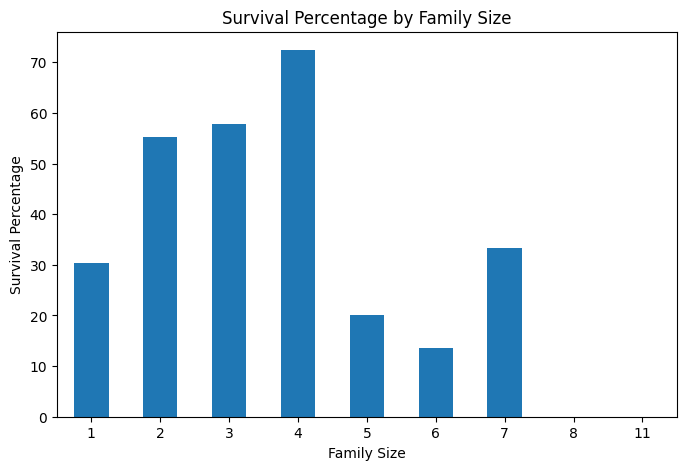

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

family_survival.plot(kind="bar")

plt.title("Survival Percentage by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)

plt.show()

In [49]:
correlation_matrix = df.corr(numeric_only=True)

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Family_Size
Survived,1.000000,-0.338481,0.543351,-0.064910,-0.035322,0.081629,0.257307,0.168240,0.003650,-0.149683,0.016639
Pclass,-0.338481,1.000000,-0.131900,-0.339898,0.083081,0.018443,-0.549500,-0.243292,0.221009,0.074053,0.065997
Sex,0.543351,-0.131900,1.000000,-0.081163,0.114631,0.245489,0.182333,0.082853,0.074115,-0.119224,0.200988
Age,-0.064910,-0.339898,-0.081163,1.000000,-0.233296,-0.172482,0.096688,0.030248,-0.031415,-0.006729,-0.245619
SibSp,-0.035322,0.083081,0.114631,-0.233296,1.000000,0.414838,0.159651,-0.059528,-0.026354,0.068734,0.890712
Parch,0.081629,0.018443,0.245489,-0.172482,0.414838,1.000000,0.216225,-0.011069,-0.081228,0.060814,0.783111
Fare,0.257307,-0.549500,0.182333,0.096688,0.159651,0.216225,1.000000,0.269335,-0.117216,-0.162184,0.217138
Embarked_C,0.168240,-0.243292,0.082853,0.030248,-0.059528,-0.011069,0.269335,1.000000,-0.148258,-0.782742,-0.046215
Embarked_Q,0.003650,0.221009,0.074115,-0.031415,-0.026354,-0.081228,-0.117216,-0.148258,1.000000,-0.499421,-0.058592
Embarked_S,-0.149683,0.074053,-0.119224,-0.006729,0.068734,0.060814,-0.162184,-0.782742,-0.499421,1.000000,0.077359


## 8. Correlation Analysis

In [50]:
print("========== FINAL CONCLUSION ==========\n")

========== FINAL CONCLUSION ==========



## 9. Final Insights